# What do we currently know about covariance completion?

**An executed research report for the transport-SPDE covariance laboratory.**

The practical question is: **when different dates reveal different parts of a curve,
what can we learn about the covariance of the whole curve and the risk of a spread?**

Our current answer has three parts:

1. More samples can improve the covariance of the **observed** fragments.
2. A completion model supplies assumptions about **never jointly observed** maturities.
   Good native-data fit cannot establish that those assumptions are correct.
3. Risk uncertainty must retain both **sampling error** and **ambiguity between completions**.

This notebook explains those statements with a worked example and the committed numerical evidence.
It is a report of synthetic experiments, not a market backtest, a new estimator, or an
infinite-dimensional statistical theorem. Saved figures and tables can be read on GitHub
without running a kernel. Executing the notebook reconstructs them from checksummed evidence;
it does not rerun the full Monte Carlo studies.


## Where this sits in the project

| Research question | What is implemented and supported by evidence? | What remains open? |
|---|---|---|
| **RQ1 — Identification** | Observation geometry, explicit equal-observed-law examples, and risk ranges across PSD completions | Which extra observations or defensible structural restrictions resolve decision-relevant ambiguity? |
| **RQ2 — Estimation** | Constrained moment fitting, Gaussian completion fitting, chronological tuning, numerical diagnostics and a Gaussian uncertainty study | Dependence, unknown noise/mean, sharper uncertainty, and operator-level guarantees |
| **RQ3 — Evaluation** | Past-only frozen forecasts and subsequent observed-data scores; a separate synthetic hedging pilot | Useful empirical forecasting/hedging performance and a validated dynamics model |

The latest increment studied here is **completion as a statistical model**. The broader
[roadmap](../docs/research-roadmap.md), [earlier completion findings](../docs/completion-continuation-findings.md)
and [hedging findings](../docs/hedging-findings.md) retain the other studies.
The existing [transport notebook](transport_covariance.ipynb) explains the trajectory-to-innovation step.


## The SPDE connection and the estimation target

For the current linear transport setup, write

$$dF_t=(AF_t+b_t)\,dt+L\,dW_t,\qquad S_t=\exp(tA),\qquad C=LL^*.$$

Here $W$ is a vector or cylindrical Brownian driver, according to the declared model;
$C$ is the instantaneous covariance of the driving perturbation. The four-mode analytical
control and the fixed infinite-rank source benchmark are different, explicitly declared cases.
The benchmark uses $A=\partial_x$, so $S_t$ shifts maturity.

After subtracting known mild drift $d_i$ and transport, the normalized innovation is

$$\xi_i=\frac{F_{t_i}-S_{\Delta_i}F_{t_{i-1}}-d_i}{\sqrt{\Delta_i}},\qquad
V_\Delta=\frac1\Delta\int_0^\Delta S_r C S_r^*\,dr.$$

For a common interval and constant source covariance, $\operatorname{Cov}(\xi_i)=V_\Delta$.
At maturity nodes $x_0,\ldots,x_{q-1}$, let $Z_i=(\xi_i(x_j))_j$ and

$$K_{ab}=\operatorname{Cov}(\xi_i(x_a),\xi_i(x_b)),\qquad
Y_i=P_i Z_i+\epsilon_i,\quad \epsilon_i\sim N(0,N_i).$$

**This completion study estimates the point kernel $K$ of $V_\Delta$.** It does not estimate
$L$ or automatically recover $C$. A loading $L$ is nonunique. A grid kernel is also not an
orthonormal Hilbert-coordinate covariance matrix. These distinctions survive spatial refinement.

The statistical experiments sample innovations directly to isolate estimation and identification.
The separate transport controls validate their SPDE connection. Sparse, noisy price levels are
not automatically transformed into fresh-noise innovation observations.


## Reproduce this report

Run from a clone of the repository, with the committed evidence directory present:

```sh
uv sync --locked --extra notebooks
uv run jupyter lab notebooks/current_findings.ipynb
```

Use **Restart Kernel and Run All Cells**. No network, market data, GPU, CVXPY, or full benchmark
rerun is needed for this notebook after installation. A lightweight verification is also available:

```sh
uv run python scripts/check_notebook.py notebooks/current_findings.ipynb
```

The following cell checks the published artifact hashes before loading data. It prints the
**numerical source revision**, which predates this presentation notebook. All figures below use
plain Matplotlib. Error bars marked MCSE describe Monte Carlo precision, not confidence intervals
for an estimated covariance.


In [1]:
import gzip
import hashlib
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from spde_covariance import condition_gaussian_kernel, fit_gaussian_completion

ROOT = next(
    (
        p
        for p in (Path.cwd(), *Path.cwd().parents)
        if (p / "experiments/results/statistical-completion/manifest.json").is_file()
    ),
    None,
)
if ROOT is None:
    raise FileNotFoundError("Start Jupyter in the repository root or its notebooks directory.")
EVIDENCE = ROOT / "experiments/results/statistical-completion"
index = json.loads((EVIDENCE / "artifact_sha256.json").read_text())
for entry in index:
    payload = (EVIDENCE / entry["published_name"]).read_bytes()
    assert hashlib.sha256(payload).hexdigest() == entry["published_sha256"]


def artifact(name):
    payload = (EVIDENCE / name).read_bytes()
    return json.loads(gzip.decompress(payload) if name.endswith(".gz") else payload)


manifest = artifact("manifest.json")
config = artifact("config.json")
points = artifact("point_rows.json.gz")
population = artifact("population.json.gz")
coverage = artifact("coverage.json.gz")
assert manifest["git_dirty"] is False
assert manifest["git_revision"].startswith("f24286a")  # This report's evidence snapshot.
assert config["replications"] == 20
assert len(points) == 360 and all(row["available"] for row in points)
COUNTS = sorted({row["training_count"] for row in points})
METHODS = {"gaussian_selected": "Gaussian likelihood", "coherent_moment": "Coherent moments"}
COLORS = {"gaussian_selected": "#1f77b4", "coherent_moment": "#c45e17"}
plt.rcParams.update(
    {
        "font.size": 11,
        "figure.dpi": 110,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": False,
    }
)


def table(headers, rows):
    rows = [[str(value) for value in row] for row in rows]
    widths = [max(len(str(h)), *(len(row[j]) for row in rows)) for j, h in enumerate(headers)]
    print(" | ".join(str(h).ljust(w) for h, w in zip(headers, widths, strict=True)))
    print("-+-".join("-" * w for w in widths))
    for row in rows:
        print(" | ".join(value.ljust(w) for value, w in zip(row, widths, strict=True)))


def mean_mcse(values):
    values = np.asarray(values, dtype=float)
    assert len(values) >= 2 and np.isfinite(values).all()
    return values.mean(), values.std(ddof=1) / np.sqrt(len(values))


def selected_rows(world, count, method):
    rows = [
        r
        for r in points
        if r["world"] == world and r["training_count"] == count and r["method"] == method
    ]
    assert len(rows) == config["replications"]
    assert len({r["replication"] for r in rows}) == len(rows)
    return {r["replication"]: r for r in rows}


def paired_metric(world, count, metric):
    gaussian = selected_rows(world, count, "gaussian_selected")
    moments = selected_rows(world, count, "coherent_moment")
    assert gaussian.keys() == moments.keys()
    return mean_mcse([gaussian[i][metric] - moments[i][metric] for i in sorted(gaussian)])


print(f"Verified {len(index)} published artifacts.")
print("Numerical source:", manifest["git_revision"])
print("Seed:", config["seed"], "| training counts:", COUNTS)
print("Point-study independent replications:", config["replications"])

Verified 33 published artifacts.
Numerical source: f24286ae6747db56a72c9cb653d455cb622a2e13
Seed: 20261030 | training counts: [128, 512, 2048]
Point-study independent replications: 20


## 1. Identification: a three-maturity example

Suppose each date reveals either $(Z_0,Z_1)$ or $(Z_1,Z_2)$, but never $(Z_0,Z_2)$ jointly.
Let $Z$ be centered Gaussian. At the population level, the observed variances and correlations give

$$K(\rho)=\begin{pmatrix}1&0.4&\rho\\0.4&1&0.4\\\rho&0.4&1\end{pmatrix}.$$

Every value of $\rho$ that makes this matrix PSD gives the **same native observation law**.
A missing covariance is not a zero covariance. The two displayed kernels below therefore
cannot be distinguished by native observations, even with arbitrarily many dates.


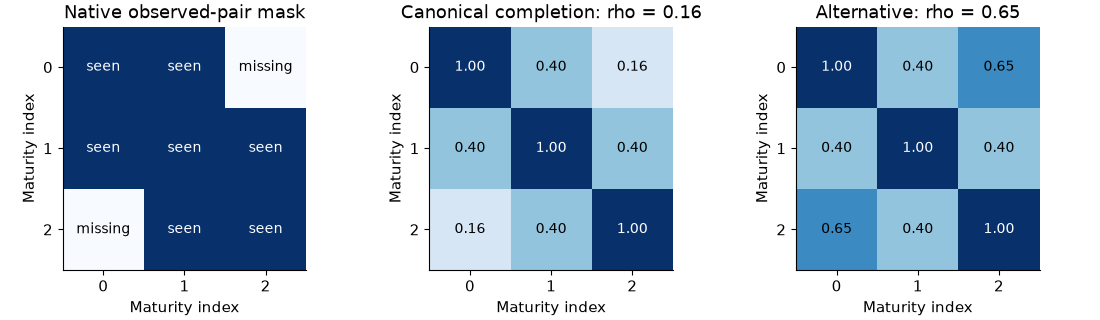

In [2]:
K_can = np.asarray(coverage["kernels"]["canonical"])
K_alt = np.asarray(coverage["kernels"]["noncanonical"])
native_mask = np.array([[True, True, False], [True, True, True], [False, True, True]])
assert np.allclose(K_can[native_mask], K_alt[native_mask])
assert np.linalg.eigvalsh(K_can)[0] > 0 and np.linalg.eigvalsh(K_alt)[0] > 0

fig, axes = plt.subplots(1, 3, figsize=(11, 3.2), layout="constrained")
for ax, matrix, title in zip(
    axes,
    [native_mask.astype(float), K_can, K_alt],
    ["Native observed-pair mask", "Canonical completion: rho = 0.16", "Alternative: rho = 0.65"],
    strict=True,
):
    ax.imshow(matrix, cmap="Blues", vmin=0, vmax=1)
    for i in range(3):
        for j in range(3):
            label = (
                ("seen" if native_mask[i, j] else "missing")
                if ax is axes[0]
                else f"{matrix[i, j]:.2f}"
            )
            ax.text(
                j,
                i,
                label,
                ha="center",
                va="center",
                color="white" if matrix[i, j] > 0.7 else "black",
                fontsize=10,
            )
    ax.set(
        xticks=range(3),
        yticks=range(3),
        xlabel="Maturity index",
        ylabel="Maturity index",
        title=title,
    )
for figure_axis in fig.axes:
    figure_axis.minorticks_off()
plt.show()

Conditioning on $Z_1$ gives the residual covariance

$$\begin{pmatrix}0.84&\rho-0.16\\\rho-0.16&0.84\end{pmatrix}\succeq0
\quad\Longleftrightarrow\quad -0.68\leq\rho\leq1.$$

The canonical Gaussian convention imposes $Z_0\perp Z_2\mid Z_1$, choosing $\rho=0.16$.
That is an additional structural assumption. For the normalized spread

$$R=(Z_0-Z_2)/\sqrt2,\qquad \operatorname{Var}(R)=1-\rho,$$

the canonical and alternative worlds have risks **0.84** and **0.35**. Exact knowledge
of the native covariance still leaves the risk range **[0, 1.68]** over all PSD completions.
The boundary includes singular PSD matrices; the likelihood fitter itself uses positive-definite kernels.


Exact-data native risk range: [0, 1.68]. More native dates cannot remove it.


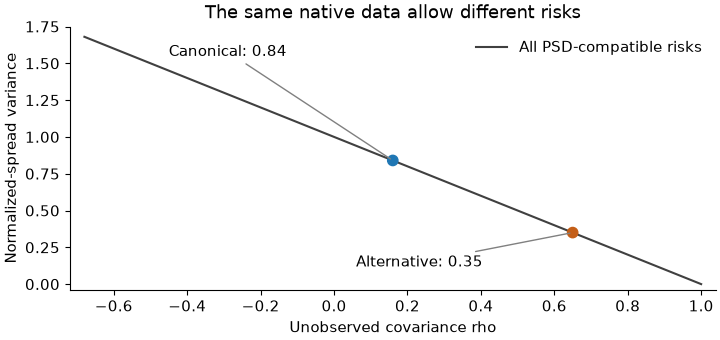

In [3]:
rho = np.linspace(-0.68, 1.0, 301)
spread = np.asarray(coverage["exposure"])
truth_risks = {
    name: float(spread @ kernel @ spread)
    for name, kernel in [("canonical", K_can), ("alternative", K_alt)]
}
assert np.allclose(list(truth_risks.values()), [0.84, 0.35])
fig, ax = plt.subplots(figsize=(7.2, 3.4), layout="constrained")
ax.plot(rho, 1 - rho, color="0.25", label="All PSD-compatible risks")
ax.scatter(
    [0.16, 0.65],
    [truth_risks["canonical"], truth_risks["alternative"]],
    color=["#1f77b4", "#c45e17"],
    s=55,
    zorder=3,
)
ax.annotate(
    "Canonical: 0.84",
    (0.16, 0.84),
    xytext=(-0.45, 1.55),
    arrowprops={"arrowstyle": "-", "color": "0.5"},
)
ax.annotate(
    "Alternative: 0.35",
    (0.65, 0.35),
    xytext=(0.06, 0.12),
    arrowprops={"arrowstyle": "-", "color": "0.5"},
)
ax.set(
    xlabel="Unobserved covariance rho",
    ylabel="Normalized-spread variance",
    title="The same native data allow different risks",
    xlim=(-0.72, 1.04),
    ylim=(-0.04, 1.75),
)
ax.legend(loc="upper right", frameon=False)
for figure_axis in fig.axes:
    figure_axis.minorticks_off()
plt.show()
print("Exact-data native risk range: [0, 1.68]. More native dates cannot remove it.")

## 2. What the statistical completion model fits

The Gaussian method fits each actually observed vector under $Z_i\sim N(0,K)$:

$$\mathcal L(K)=\frac{1}{2n}\sum_i\left[\log\det\Sigma_i+
Y_i^\top\Sigma_i^{-1}Y_i+m_i\log(2\pi)\right],\qquad
\Sigma_i=P_iKP_i^\top+N_i.$$

It declares a fixed graph with zeros in $Q=K^{-1}$ outside observed fragment connections,
and adds the explicit penalty

$$\frac\lambda2\{\operatorname{tr}(TQ)-\log\det(TQ)-q\},\qquad T\succ0.$$

The reference $T$ is external or training-only; positive $\lambda$ changes the estimand.
The penalty bracket is twice the Gaussian KL divergence from covariance $T$ to $K$.
The alternative coherent-moment method fits noise-corrected products with a Frobenius penalty.
**Their comparison evaluates whole fitting policies, not likelihood alone.**

Missing-data EM retains full support and audits local stationarity and initializations.
The noisy observed likelihood is not claimed globally convex. Its local criterion is distinct
from the coherent moment solver's convex optimization certificate.

Here is a small independent demonstration, with a predeclared penalty rather than validation tuning.
It is not another replication of the archived study.


In [4]:
rng = np.random.default_rng(20261030)
demo_count, demo_noise = 256, 0.001
demo_rows = tuple(np.array([i % 2, i % 2 + 1]) for i in range(demo_count))
demo_parent = rng.multivariate_normal(np.zeros(3), K_can + demo_noise * np.eye(3), demo_count)
demo_values = tuple(demo_parent[i, row] for i, row in enumerate(demo_rows))
demo_noises = tuple(demo_noise * np.eye(2) for _ in demo_rows)
demo_fit = fit_gaussian_completion(
    demo_values,
    demo_rows,
    noise_covariances=demo_noises,
    cliques=((0, 1), (1, 2)),
    reference_kernel=np.eye(3),
    regularization=0.5 / demo_count,
)
assert demo_fit.converged and np.linalg.eigvalsh(demo_fit.kernel)[0] > 0
assert abs(demo_fit.precision[0, 2]) < 1e-10
conditional = condition_gaussian_kernel(
    demo_fit.kernel,
    demo_values[0],
    demo_rows[0],
    noise_covariance=demo_noises[0],
    target_nodes=[2],
)
print("Fitted signal kernel (one illustration):")
print(np.array2string(demo_fit.kernel, precision=4))
print("Local stationarity residual:", f"{demo_fit.diagnostics['relative_stationarity']:.2e}")
print("Missing-node conditional mean:", conditional.mean)
print("Missing-node conditional variance:", conditional.covariance)
print(
    "This plug-in prediction conditions on the fitted graph and K; it excludes parameter uncertainty."
)

Fitted signal kernel (one illustration):
[[1.0026 0.4109 0.1321]
 [0.4109 0.9229 0.2967]
 [0.1321 0.2967 0.8653]]
Local stationarity residual: 5.36e-07
Missing-node conditional mean: [0.02493201]
Missing-node conditional variance: [[0.76998532]]
This plug-in prediction conditions on the fitted graph and K; it excludes parameter uncertainty.


## 3. What the seven-maturity numerical study found

The committed study uses maturities **0, 0.5, …, 3 years**, native fragments
**{0,1,2,3}** and **{3,4,5,6}**, weekly innovations, and known fresh noise variance **0.001**.
Two fixed infinite-rank SPDE source worlds and a canonical Gaussian control share the native law.
The control is a grid Gaussian model; its membership in an SPDE source class is not asserted.

| Stage | Observations (one-based indices) | Role |
|---|---|---|
| Training | First 128, 512, or 2,048 | Nested prefixes, same parent observations |
| Validation | 2,049–2,176 | Select among predeclared penalties using native observations only |
| Test | 2,177–2,688 | Untouched native views and a separately disclosed complete-panel audit |

There are **20 independent paired replications**. Methods, source worlds, sample sizes and
individual dates are not extra independent replications. The identical native laws are coupled
to give exactly identical native input arrays, so fitting/selection cannot access world labels.
The graph stays fixed when complete audit observations are scored.

The full panel is a measurement augmentation for evaluation. It is not native information
retroactively available to fit or tune the model.


In [5]:
mask = np.asarray(population["observed_mask"], dtype=bool)
K_minus = np.asarray(population["kernels"]["source_minus"])
K_plus = np.asarray(population["kernels"]["source_plus"])
assert np.allclose(K_minus[mask], K_plus[mask], rtol=0, atol=2e-14)
for count in COUNTS:
    left = selected_rows("source_minus", count, "gaussian_selected")
    right = selected_rows("source_plus", count, "gaussian_selected")
    for replication in left:
        for key in ("training_sha256", "kernel_sha256", "native_test_sha256"):
            assert left[replication][key] == right[replication][key]
print("Native unique covariance pairs, including diagonals:", np.count_nonzero(np.triu(mask)))
print(
    "Maximum population native-block discrepancy:",
    f"{population['observed_law_max_difference']:.2e}",
)
print(
    "Verified: native training, selected kernels and native test inputs match across SPDE worlds."
)

Native unique covariance pairs, including diagonals: 19
Maximum population native-block discrepancy: 1.55e-15
Verified: native training, selected kernels and native test inputs match across SPDE worlds.


### Sampling error decreases in the correctly specified control

Kernel errors below are **absolute weighted grid Frobenius norms**:

$$\|W^{1/2}(\widehat K-K)W^{1/2}\|_F,$$

with common normalized physical quadrature weights. Observed and missing errors restrict the
same weighted matrix to those regions; they are not region-wise percentages. These are not
Hilbert-operator errors. Bars are **± one replication MCSE**. A small MCSE measures precision of
the experiment's mean, not identification or uncertainty about the fitted kernel.


N    | Method              | Complete weighted kernel error ± MCSE
-----+---------------------+--------------------------------------
128  | Gaussian likelihood | 0.07484 ± 0.01127                    
128  | Coherent moments    | 0.10354 ± 0.01329                    
512  | Gaussian likelihood | 0.04893 ± 0.00814                    
512  | Coherent moments    | 0.06669 ± 0.00684                    
2048 | Gaussian likelihood | 0.02197 ± 0.00422                    
2048 | Coherent moments    | 0.03325 ± 0.00413                    


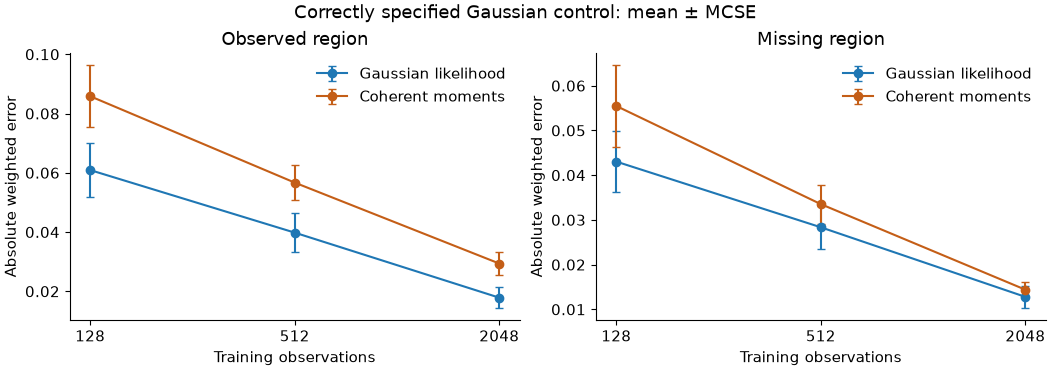

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.7), layout="constrained")
for ax, metric, title in zip(
    axes, ["observed_error", "missing_error"], ["Observed region", "Missing region"], strict=True
):
    for method, label in METHODS.items():
        stats = [
            mean_mcse(
                [r[metric] for r in selected_rows("canonical_control", count, method).values()]
            )
            for count in COUNTS
        ]
        ax.errorbar(
            COUNTS,
            [s[0] for s in stats],
            yerr=[s[1] for s in stats],
            marker="o",
            capsize=3,
            label=label,
            color=COLORS[method],
        )
    ax.set(
        xscale="log",
        xticks=COUNTS,
        xticklabels=[str(n) for n in COUNTS],
        xlabel="Training observations",
        ylabel="Absolute weighted error",
        title=title,
    )
    ax.legend(frameon=False)
fig.suptitle("Correctly specified Gaussian control: mean ± MCSE")
for figure_axis in fig.axes:
    figure_axis.minorticks_off()
plt.show()

rows = []
for count in COUNTS:
    for method, label in METHODS.items():
        mean, se = mean_mcse(
            [
                r["weighted_kernel_error"]
                for r in selected_rows("canonical_control", count, method).values()
            ]
        )
        rows.append([count, label, f"{mean:.5f} ± {se:.5f}"])
table(["N", "Method", "Complete weighted kernel error ± MCSE"], rows)

### Prediction scores improve here; missing-region superiority is unresolved

Compare methods on **the same future observations within each world and measurement design**.
The plot shows Gaussian minus coherent-moment mean negative log likelihood (NLL): negative is
better for the Gaussian policy. The native and complete audit panels have different dimensions;
their raw NLL levels should not be compared as if they were the same score.

Pairing is done by replication **before** calculating MCSE. Shared world labels or dates
are never treated as independent replications.


Metric at N=2048      | Gaussian minus moments ± MCSE
----------------------+------------------------------
native_nll            | -0.605088 ± 0.170024         
bridge_nll            | -1.218669 ± 0.322738         
weighted_kernel_error | -0.011281 ± 0.003281         
missing_error         | -0.001605 ± 0.002033         


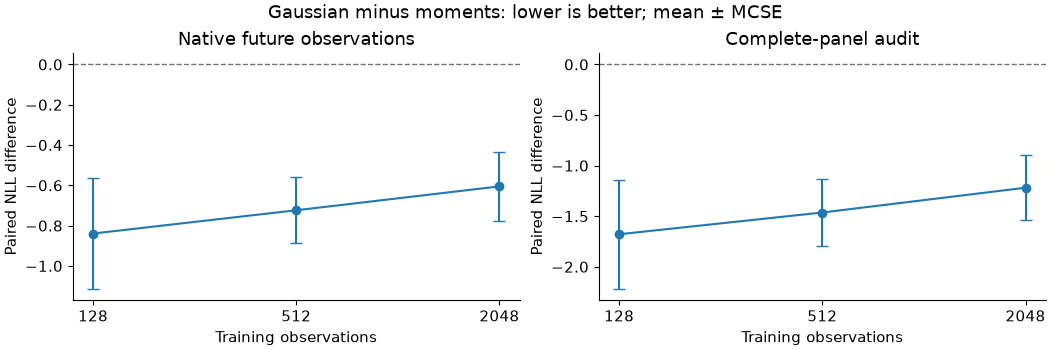

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.5), layout="constrained")
for ax, metric, title in zip(
    axes,
    ["native_nll", "bridge_nll"],
    ["Native future observations", "Complete-panel audit"],
    strict=True,
):
    stats = [paired_metric("canonical_control", count, metric) for count in COUNTS]
    ax.errorbar(
        COUNTS,
        [s[0] for s in stats],
        yerr=[s[1] for s in stats],
        marker="o",
        capsize=4,
        color="#1f77b4",
    )
    ax.axhline(0, color="0.45", linestyle="--", linewidth=1)
    ax.set(
        xscale="log",
        xticks=COUNTS,
        xticklabels=[str(n) for n in COUNTS],
        xlabel="Training observations",
        ylabel="Paired NLL difference",
        title=title,
    )
fig.suptitle("Gaussian minus moments: lower is better; mean ± MCSE")
for figure_axis in fig.axes:
    figure_axis.minorticks_off()
plt.show()

metrics = ["native_nll", "bridge_nll", "weighted_kernel_error", "missing_error"]
contrasts = {metric: paired_metric("canonical_control", 2048, metric) for metric in metrics}
table(
    ["Metric at N=2048", "Gaussian minus moments ± MCSE"],
    [[metric, f"{value[0]:+.6f} ± {value[1]:.6f}"] for metric, value in contrasts.items()],
)
assert np.isclose(contrasts["missing_error"][0], -0.001604813, atol=1e-8)

The correctly specified control shows improved native NLL and complete-kernel error for this
Gaussian policy. The missing-error contrast at $N=2048$ is only about $-0.00160\pm0.00203$:
**these replications do not resolve a missing-region advantage**. This is not a universal method
ranking or a claim that likelihood alone caused the improvement: the KL and Frobenius
regularizations differ even though they share a training-only reference and observed validation.

All 360 candidate fits were available. All 540 Gaussian initialization attempts reached the
declared local criterion; the largest selected relative residual was about $8.53\times10^{-7}$.
This numerical result does not certify a global optimum or a sampling error bound.


## 4. Native validation cannot verify the missing-block assumption

The construction is not confined to the three-node illustration: two true-point SPDE sources
give the same native covariance but different missing covariance. A population canonical
completion has the discrepancies below. These are **deterministic population diagnostics**,
not fitted Monte Carlo errors or tests based on available native data.

The complete-panel Gaussian KL is positive against both SPDE worlds despite exactly shared
native laws. It is zero, to floating-point rounding, against the correctly specified control.
More native samples can learn the shared partial covariance but cannot choose between these
worlds. Criticizing the hidden convention requires informative bridge measurements or additional
defensible restrictions, not more evaluations of the same native likelihood.


In [8]:
world_names = {
    "source_minus": "SPDE source minus",
    "source_plus": "SPDE source plus",
    "canonical_control": "Canonical Gaussian control",
}
table(
    ["World", "Canonical weighted error", "Canonical full-panel KL"],
    [
        [
            label,
            f"{population['canonical_structural_error'][world]:.7f}",
            f"{population['canonical_bridge_gaussian_kl'][world]:.6g}",
        ]
        for world, label in world_names.items()
    ],
)
print("The canonical control is a grid Gaussian control, not an asserted SPDE source.")

World                      | Canonical weighted error | Canonical full-panel KL
---------------------------+--------------------------+------------------------
SPDE source minus          | 0.0027066                | 0.244985               
SPDE source plus           | 0.0032210                | 0.290495               
Canonical Gaussian control | 0.0000000                | 3.55271e-15            
The canonical control is a grid Gaussian control, not an asserted SPDE source.


## 5. Sampling uncertainty and completion ambiguity must coexist

The separate three-node experiment constructs simultaneous Gaussian variance bands and propagates
them through **all PSD completions**, without imposing the canonical graph. Its trace bound
comes from the diagonal confidence bands. This is different from the plug-in conditional
prediction variance printed earlier, which assumes a fitted $K$.

It uses 500 independent replications **per design/sample-size stratum**. Sample sizes are nested
and complete/native views share parent draws. The six strata are paired; the 3,000 numerical
intervals are not 3,000 independent Monte Carlo replications. Native data are compatible with
both three-node worlds. Complete data distinguish them and are generated/evaluated under the
canonical world here; alternative-world complete coverage is therefore unavailable.


N    | Design   | Width ± MCSE      | Partial covered | Canonical risk covered
-----+----------+-------------------+-----------------+-----------------------
128  | native   | 3.38399 ± 0.01773 | 490/500         | 500/500               
128  | complete | 1.46593 ± 0.00546 | 493/500         | 500/500               
512  | native   | 2.50934 ± 0.00680 | 487/500         | 500/500               
512  | complete | 0.70124 ± 0.00135 | 489/500         | 500/500               
2048 | native   | 2.10707 ± 0.00290 | 487/500         | 500/500               
2048 | complete | 0.34750 ± 0.00035 | 488/500         | 500/500               
For 500/500, the exact binomial 95% interval is [0.99265, 1.00000].
Native risk intervals also contain the alternative-world risk in all 500 cases per count.


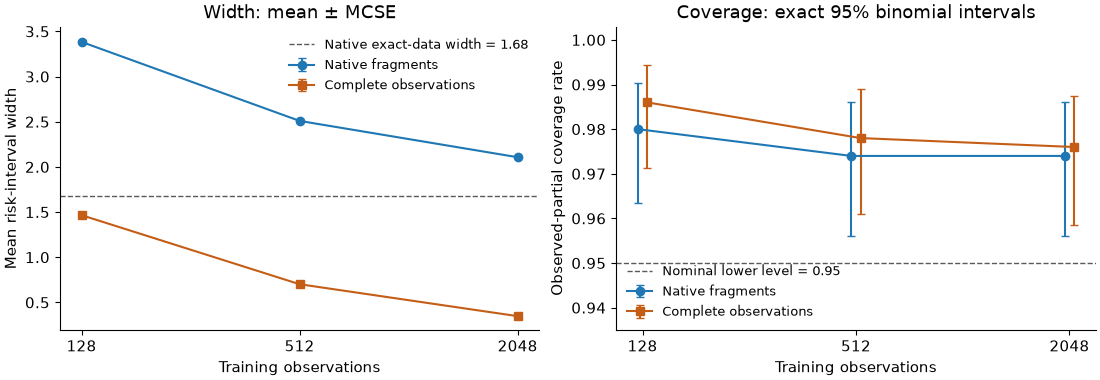

In [9]:
strata = {(coverage["design"], coverage["training_count"]): coverage}
for stratum in coverage["resolution_study"]:
    key = (stratum["design"], stratum["training_count"])
    if key in strata:
        assert strata[key]["mean_width"] == stratum["mean_width"]
    strata[key] = stratum
assert len(strata) == 6

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), layout="constrained")
for design, label, color, marker in [
    ("native", "Native fragments", "#1f77b4", "o"),
    ("complete", "Complete observations", "#c45e17", "s"),
]:
    values = [strata[(design, count)] for count in COUNTS]
    for value in values:
        assert len(value["records"]) == 500
        widths = [r["width"] for r in value["records"] if r["interval_available"]]
        assert len(widths) == 500
        assert np.allclose(mean_mcse(widths), [value["mean_width"], value["width_mcse"]])
    axes[0].errorbar(
        COUNTS,
        [v["mean_width"] for v in values],
        yerr=[v["width_mcse"] for v in values],
        label=label,
        color=color,
        marker=marker,
        capsize=3,
    )
    rates = np.array([v["partial_coverage"]["rate"] for v in values])
    bounds = np.array([v["partial_coverage"]["interval_95"] for v in values])
    x = np.array(COUNTS) * (0.97 if design == "native" else 1.03)
    axes[1].errorbar(
        x,
        rates,
        yerr=np.vstack((rates - bounds[:, 0], bounds[:, 1] - rates)),
        label=label,
        color=color,
        marker=marker,
        capsize=3,
    )
axes[0].axhline(
    1.68, linestyle="--", color="0.35", linewidth=1, label="Native exact-data width = 1.68"
)
axes[1].axhline(0.95, linestyle="--", color="0.35", linewidth=1, label="Nominal lower level = 0.95")
axes[0].set(ylabel="Mean risk-interval width", title="Width: mean ± MCSE")
axes[1].set(
    ylabel="Observed-partial coverage rate",
    ylim=(0.935, 1.003),
    title="Coverage: exact 95% binomial intervals",
)
for ax in axes:
    ax.set(
        xscale="log",
        xticks=COUNTS,
        xticklabels=[str(n) for n in COUNTS],
        xlabel="Training observations",
    )
    ax.legend(frameon=False, fontsize=9)
for figure_axis in fig.axes:
    figure_axis.minorticks_off()
plt.show()

rows = []
for count in COUNTS:
    for design in ["native", "complete"]:
        value = strata[(design, count)]
        partial = value["partial_coverage"]
        risk = value["risk_coverage_all"]["canonical"]
        rows.append(
            [
                count,
                design,
                f"{value['mean_width']:.5f} ± {value['width_mcse']:.5f}",
                f"{partial['successes']}/{partial['count']}",
                f"{risk['successes']}/{risk['count']}",
            ]
        )
table(["N", "Design", "Width ± MCSE", "Partial covered", "Canonical risk covered"], rows)
ci = coverage["risk_coverage_all"]["canonical"]["interval_95"]
print(f"For 500/500, the exact binomial 95% interval is [{ci[0]:.5f}, {ci[1]:.5f}].")
print("Native risk intervals also contain the alternative-world risk in all 500 cases per count.")

Native widths decrease from **3.38 to 2.11**, with a nonzero population identification width
of **1.68**. Complete-view widths decrease from **1.47 to 0.35** and have no such missing-pair
ambiguity. The finite points do not by themselves prove a limiting rate.

Observed-partial coverage is 97.4–98.6%, and relevant risk coverage is 500/500 in each stratum.
The intervals are conservative here. **500/500 does not establish a true coverage probability
of 100%**, and a plug-in MCSE of zero at that outcome does not remove Monte Carlo uncertainty.

The nominal simultaneous guarantee assumes independent, centered, common-covariance Gaussian
rows, deterministic masks, and known fresh Gaussian noise. Bonferroni allocates one error budget
across scalar probes/noise groups; it does not treat covariance entries as independent samples.
Numerical outer risk bounds retain repaired dual diagnostics and primal witnesses. Floating-point
quantiles and feasibility checks are not interval-arithmetic proofs. These conditions do not
automatically hold for market returns.


## 6. What is established, and what should we do next?

| Question | Current answer | Meaning for the next step |
|---|---|---|
| Can we estimate observed covariance? | Yes in controlled examples; errors decline with sampling and the implementation passes independent checks. | Keep numerical error, sampling error, and representation error separate. |
| Do the observations identify the full kernel? | Not for the native fragment designs; explicit same-law SPDE worlds have different unseen covariance and risks. | Add joint maturity measurements or state a structural prior openly. |
| Is canonical completion a statistically testable model? | It is a fitted Gaussian conditional-independence model. Native validation tests observed predictions, not never-seen pairs. | Design a bridge holdout that can actually test the hidden restriction. |
| Is likelihood fitting universally better? | No such claim follows. It improves selected metrics in this study; missing-region superiority is unresolved. | Use fair paired controls and compare complete policies, including their priors. |
| Do we have useful forecast/hedge performance? | Prior synthetic studies show updating can help; adaptive windows and the conservative hedge rule have no demonstrated consistent advantage. | Evaluate decisions and future scores directly rather than inferring them from kernel error. |
| Are we ready to claim an empirical futures model? | No. The contract-data interface exists, but this is not market calibration or a trading backtest. | Establish observation maps, drift, timing, dependence, noise and usable histories first. |

The highest-value implementation targets are:

1. **Bridge-based model criticism:** reserve informative joint observations to test hidden-block
   predictions, keeping their graph and tuning roles explicit.
2. **Sharper decision-relevant uncertainty:** reduce avoidable conservatism while preserving
   unidentified risks; compare like-for-like trace/source assumptions before judging robust hedges.
3. **An empirical observation model:** specify how contract prices produce observations of
   adjusted innovations, including irregular time and dependence, before reusing Gaussian coverage.

The genuinely infinite-dimensional phase still needs one fixed operator model, controlled
representation/tail/semigroup errors, and statistical assumptions under refinement. A larger
finite matrix alone does not establish that theory. The nonlinear and stochastic-volatility
extensions are possible later choices, not prerequisites for a substantive operator problem.


## Evidence and further reading

- [Full statistical-completion report and artifacts](../experiments/results/statistical-completion/report.md)
  · [audited findings](../docs/statistical-completion-findings.md)
  · [model/protocol](../docs/statistical-completion.md)
  · [runnable high-level workflow](../examples/statistical_completion.py).
- [Fixed infinite-rank transport](../docs/infinite-transport.md)
  · [completion ablations/refinement/forecast findings](../docs/completion-continuation-findings.md)
  · [identification-to-hedging findings](../docs/hedging-findings.md)
  · [future research roadmap](../docs/research-roadmap.md).
- The methodological ingredients are established:
  [Waghmare–Panaretos, covariance completion](https://arxiv.org/abs/2107.07350),
  [Dempster–Laird–Rubin, EM](https://academic.oup.com/jrsssb/article/39/1/1/7027539),
  and [decomposable Gaussian covariance estimation](https://arxiv.org/abs/0903.1283).

The current contribution is a coherent, reproducible research workflow and explicit numerical
evidence about identification, fitting and evaluation. Novel methodology, market performance,
and infinite-dimensional statistical guarantees remain separate research claims.
